# Inference demo

In this notebook, we will demonstrate how to calculate the representation layers predicted by the FireCLR to perform the downstream tasks of detecting burned areas and indicating burned severity at the Mesa fire. The training and validating steps are shown by using a small region in the Mesa fire in this demo due to the computing time and data size. If you are interesting in reproducing on the full dataset, please check out our [Git repository](https://github.com/spaceml-org/FireCLR-Wildfires.git).

The demonstration will include the applications of the representation layers from Sentinel-2 at the 2018 Mesa fire in Idaho. However, due to the limitation, we could only provide the raw training and validation datasets for this demo from the Sentinel-2.

The full pre-trained models and predicted representation layers of the Sentinel-2 and PlanetScope are hosted in a publicly accessible [Google Drive folder](https://drive.google.com/drive/folders/1C6EL6-P9YN6KxLjho9WHrx8uvXwOdzSZ?usp=sharing). If you are interested in more details about the study, please check our [publication](https://arxiv.org/abs/2211.14654) at the NeurIPS 2022. Or if playing with more models and datasets, please get in touch with the corresponding author by email.

# Prepare the environment and get the data ready

The models were trained and run with GPU. To enable your notebook to run with GPU, go to Edit at the navigation bar, then in the drop-down options open the Notebook settings, choose the hardware accelerator to GPU

In [ ]:
!nvidia-smi

Mon Nov 28 00:36:27 2022       
+-----------------------------------------------------------------------------+
| NVIDIA-SMI 460.32.03    Driver Version: 460.32.03    CUDA Version: 11.2     |
|-------------------------------+----------------------+----------------------+
| GPU  Name        Persistence-M| Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp  Perf  Pwr:Usage/Cap|         Memory-Usage | GPU-Util  Compute M. |
|                               |                      |               MIG M. |
|===============================+======================+======================|
|   0  Tesla T4            Off  | 00000000:00:04.0 Off |                    0 |
| N/A   55C    P8    10W /  70W |      0MiB / 15109MiB |      0%      Default |
|                               |                      |                  N/A |
+-------------------------------+----------------------+----------------------+
                                                                               
+-------

## Install and import the required python libraries

In [ ]:
! pip install --quiet gdal rasterio geopandas

     |████████████████████████████████| 19.3 MB 1.2 MB/s 
     |████████████████████████████████| 1.0 MB 14.4 MB/s 
     |████████████████████████████████| 16.7 MB 11.8 MB/s 
     |████████████████████████████████| 6.3 MB 31.9 MB/s 


In [ ]:
import glob
import time
import os
import sys
import math
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio as rio
from rasterio import features
from rasterio.features import rasterize
import rasterio.plot as rioplt
from osgeo import gdal
import osr
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_curve, auc, f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.cluster import KMeans
import torch
from torch import nn
from torch.utils.data import DataLoader

## Get the data

If you’re running this tutorial in **Google Colab** you need to *'add a shortcut to your Google Drive’* from our public [Google Drive folder](https://drive.google.com/drive/folders/1C6EL6-P9YN6KxLjho9WHrx8uvXwOdzSZ?usp=sharing
and mount that directory with the following code:

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive', force_remount=True)

public_folder = '/content/drive/My Drive/FireCLR-Wildfires'
assert os.path.exists(public_folder), "Add a shortcut to the publice Google Drive folder: https://drive.google.com/drive/folders/1C6EL6-P9YN6KxLjho9WHrx8uvXwOdzSZ?usp=sharing"

Mounted at /content/drive


Alternatively, you can download the Demo.zip from the github repo which should contain what is needed for this demo.

## Configure the paths and environment

In [ ]:
# prepare the output paths
! mkdir /content/drive/My\ Drive/FireCLR-Wildfires-Demo/
! mkdir /content/drive/My\ Drive/FireCLR-Wildfires-Demo/ml_ready/
! mkdir /content/drive/My\ Drive/FireCLR-Wildfires-Demo/ml_ready/S2_pre_fire/
! mkdir /content/drive/My\ Drive/FireCLR-Wildfires-Demo/ml_ready/S2_post_fire/
! mkdir /content/drive/My\ Drive/FireCLR-Wildfires-Demo/representations/
! mkdir /content/drive/My\ Drive/FireCLR-Wildfires-Demo/distance_maps/

In [ ]:
sys.path.append('/content/drive/My Drive/FireCLR-Wildfires/Demo/func/')
from models.cnn_simclr import CNN_SimCLR
from models.simclr import SimCLR
from utils import load_data
from utils import processing_data
from utils import validation

## Load the data

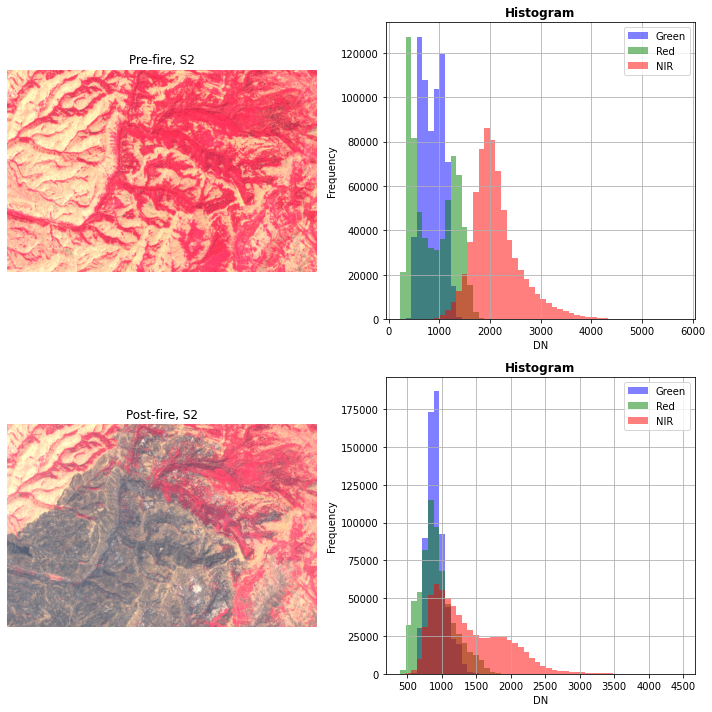

In [ ]:
# change the directories to your local paths if you're running in a jupyter notebook
# load the S2 false color image (NIR, R, G) as a demo
s2_pre_fire_dir = '/content/drive/My Drive/FireCLR-Wildfires/Demo/raw_data/S2_pre_fire.tif'
s2_post_fire_dir = '/content/drive/My Drive/FireCLR-Wildfires/Demo/raw_data/S2_post_fire.tif'
s2_pre_fire = rio.open(s2_pre_fire_dir)
s2_post_fire = rio.open(s2_post_fire_dir)
fig, ax = plt.subplots(2,2, figsize=(10,10), tight_layout=True)
s2_pre_fire_cir = s2_pre_fire.read([4,3,2])
s2_post_fire_cir = s2_post_fire.read([4,3,2])
rioplt.show(3*s2_pre_fire_cir/5000, ax=ax[0,0]) ## adjusted for visualization
rioplt.show_hist(s2_pre_fire_cir, bins=50, histtype='stepfilled',lw=0.0, stacked=False, alpha=0.5, ax=ax[0,1],label=["NIR","Red","Green"])
ax[0,0].set_title("Pre-fire, S2")
ax[0,0].axis("off")
rioplt.show(3*s2_post_fire_cir/5000, ax=ax[1,0]) ## adjusted for visualization
rioplt.show_hist(s2_post_fire_cir, bins=50, histtype='stepfilled',lw=0.0, stacked=False, alpha=0.5, ax=ax[1,1],label=["NIR","Red","Green"])
ax[1,0].set_title("Post-fire, S2")
ax[1,0].axis("off")
plt.show()

In [ ]:
# Start processing (tile and normalize) the validation data, output under /content/drive/My Drive/FireCLR-Wildfires-Demo/ml_ready/
# this process will take around 1.5 minutes
# pre Mesa fire
processing_data.create_image_tile(s2_pre_fire_dir, stride_size = 8, out_dir = "/content/drive/My Drive/FireCLR-Wildfires-Demo/ml_ready/S2_pre_fire/")
# post Mesa fire
processing_data.create_image_tile(s2_post_fire_dir, stride_size = 8, out_dir = "/content/drive/My Drive/FireCLR-Wildfires-Demo/ml_ready/S2_post_fire/")

Loading image: Mesa - S2_pre_fire
Loading image is done!
Start tiling the image...
The numbers of rows and columns after tiling are (79, 123)
After tiling, the size of data matrix becomes:  (4, 32, 32)
Loading image: Mesa - S2_post_fire
Loading image is done!
Start tiling the image...
The numbers of rows and columns after tiling are (79, 123)
After tiling, the size of data matrix becomes:  (4, 32, 32)


# Validation

## Computing the representation layers

Vectors in the latent space using the pre-trained model on the Sentinel-2

In [ ]:
# computation will be on the GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)

Using device: cuda


In [ ]:
# load the pre-trained model
saved_model = torch.load('/content/drive/My Drive/FireCLR-Wildfires/Saved_Models/S2_Mesa.tar', map_location = device)

state_dict = saved_model['state_dict']

for name in state_dict:
    print(name)


module.encoder.conv.0.0.weight
module.encoder.conv.0.0.bias
module.encoder.conv.0.2.weight
module.encoder.conv.0.2.bias
module.encoder.conv.1.0.weight
module.encoder.conv.1.0.bias
module.encoder.conv.1.2.weight
module.encoder.conv.1.2.bias
module.projection.0.weight
module.projection.0.bias
module.projection.2.weight
module.projection.2.bias


In [ ]:
for k in list(state_dict.keys()):
    if k.startswith('module.encoder.'):
        print(k)
        print(state_dict[k].shape)
        state_dict[k[len('module.encoder.'):]] = state_dict[k]

module.encoder.conv.0.0.weight
torch.Size([32, 4, 3, 3])
module.encoder.conv.0.0.bias
torch.Size([32])
module.encoder.conv.0.2.weight
torch.Size([32, 32, 3, 3])
module.encoder.conv.0.2.bias
torch.Size([32])
module.encoder.conv.1.0.weight
torch.Size([256, 32, 3, 3])
module.encoder.conv.1.0.bias
torch.Size([256])
module.encoder.conv.1.2.weight
torch.Size([256, 256, 3, 3])
module.encoder.conv.1.2.bias
torch.Size([256])


In [ ]:
model = CNN_SimCLR(validation=True, n_channels=4, tile_size=32, out_dim=256).to(device) #FireCLR

In [ ]:
log = model.load_state_dict(state_dict, strict=False)

In [ ]:
# freeze all layers but the projection head
for name, param in model.named_parameters():
    if name not in ['projection.0.weight', 'projection.0.bias','projection.2.weight','projection.2.bias']:
        param.requires_grad = False

parameters = list(filter(lambda p: p.requires_grad, model.parameters()))

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), 0.0003, weight_decay= 1e-4)
criterion = torch.nn.CrossEntropyLoss().to(device)

In [ ]:
# computing the representation
# prefire
prefire_list = glob.glob("/content/drive/My Drive/FireCLR-Wildfires-Demo/ml_ready/S2_pre_fire/"+"*.npy")
prefire_list.sort()
prefire_dataset = load_data.Load_Transformed_Dataset(prefire_list)
pre_logits_list = []
empty_arr = np.empty((256,))
empty_arr[:] = np.nan
model.eval()
start_time = time.time()
for _, x_batch in enumerate(prefire_dataset):
    if np.isnan(x_batch).sum() != 0:
        pre_logits_list.append(empty_arr)
    else:
        x_batch = torch.tensor(x_batch)
        x_batch = x_batch.reshape(1, 4, 32, 32).to(device,dtype=torch.float)
        logits = model.forward(x_batch)
        pre_logits_list.append(logits.cpu().detach().numpy().reshape(256,))

print("Prediction is done. It takes %.2f minutes" %((time.time()-start_time)/60))

Prediction is done. It takes 0.60 minutes


In [ ]:
# save the representation under your folder /content/drive/My Drive/FireCLR-Wildfires-Demo/representations/
np.save("/content/drive/My Drive/FireCLR-Wildfires-Demo/representations/S2_pre_fire_representation.npy",pre_logits_list)

In [ ]:
postfire_list = glob.glob("/content/drive/My Drive/FireCLR-Wildfires-Demo/ml_ready/S2_post_fire/"+"*.npy")
postfire_list.sort()
postfire_dataset = load_data.Load_Transformed_Dataset(postfire_list)
post_logits_list = []
empty_arr = np.empty((256,))
empty_arr[:] = np.nan
model.eval()
start_time = time.time()
for _, x_batch in enumerate(postfire_dataset):
    if np.isnan(x_batch).sum() != 0:

        post_logits_list.append(empty_arr)
    else:
        x_batch = torch.tensor(x_batch)
        x_batch = x_batch.reshape(1, 4, 32, 32).to(device,dtype=torch.float) #change the datatype to torch.FloatTensor
        logits = model.forward(x_batch)
        post_logits_list.append(logits.cpu().detach().numpy().reshape(256,))

print("Prediction is done. It takes %.2f minutes" %((time.time()-start_time)/60))

Prediction is done. It takes 0.51 minutes


In [ ]:
np.save("/content/drive/My Drive/FireCLR-Wildfires-Demo/representations/S2_post_fire_representation.npy",post_logits_list)

In [ ]:
# pre_logits_list = np.load("/content/drive/My Drive/FireCLR-Wildfires-Demo/representations/S2_pre_fire_representation.npy")
# post_logits_list = np.load("/content/drive/My Drive/FireCLR-Wildfires-Demo/representations/S2_post_fire_representation.npy")

In [ ]:
def cosine_distance(a,b):
    a_dot_b = np.dot(a,b.T)
    a_norm = np.sqrt(np.sum(a*a))
    b_norm = np.sqrt(np.sum(b*b))
    return a_dot_b/(a_norm*b_norm)

In [ ]:
# reshape the pre and post fire data
empty_arr = np.empty((256,))
empty_arr[:] = np.nan
new_post_logits_list = []
for i in post_logits_list:
    if type(i)==float:
        new_post_logits_list.append(empty_arr)
    else:
        new_post_logits_list.append(i.reshape(256,))

new_pre_logits_list = []
for i in pre_logits_list:
    if type(i)==float:
        new_pre_logits_list.append(empty_arr)
    else:
        new_pre_logits_list.append(i.reshape(256,))

In [ ]:
# calculate cosine distance
cos_dist_list = []
for i in range(len(post_logits_list)):
    post_i = post_logits_list[i]
    pre_i = pre_logits_list[i]
    if type(pre_i)==float or type(post_i)==float: #check if the array is np.nan
        cos_dist_list.append(np.nan)
    else:
        cos_dist = cosine_distance(pre_i,post_i)
        cos_dist_list.append(cos_dist)
        #arr1.dot(arr2.T)/ (np.linalg.norm(arr1, axis=1) * np.linalg.norm(arr2))

In [ ]:
cos_dist_arr = np.asarray(cos_dist_list).reshape(79, 123) # reshape the cosine distance to a map

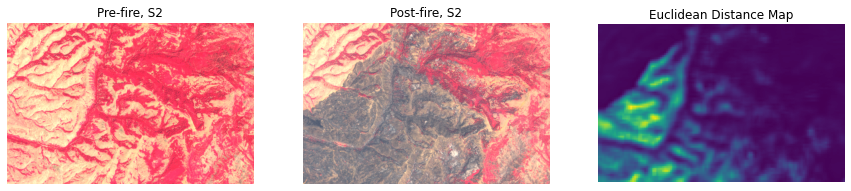

In [ ]:
# visualize the cosine distance map

fig, ax = plt.subplots(1,3,figsize=(15, 4))

rioplt.show(3*s2_pre_fire_cir/5000, ax=ax[0]) ## adjusted for visualization
ax[0].set_title("Pre-fire, S2")
ax[0].axis("off")

rioplt.show(3*s2_post_fire_cir/5000, ax=ax[1]) ## adjusted for visualization
ax[1].set_title("Post-fire, S2")
ax[1].axis("off")

ax[2].imshow((1-cos_dist_arr)*1000,cmap='viridis') ## adjusted for visualization
ax[2].axis("off")
ax[2].set_title("Euclidean Distance Map")

plt.show()


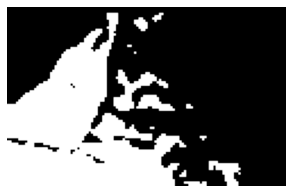

In [ ]:
# Kmeans clusterring on the represnetation layers

diff_arr = np.asarray(new_post_logits_list)-np.asarray(new_pre_logits_list)
kmeans_2_diff = KMeans(n_clusters=2)
diff_arr[np.isnan(diff_arr)] = 0.0
kmeans_2_diff.fit(diff_arr)

kmeans_2_diff_change_labels = kmeans_2_diff.labels_.reshape(79, 123)

plt.figure(figsize=(5,4))
plt.imshow(kmeans_2_diff_change_labels, cmap='Greys_r')
plt.axis("off")
plt.show()

In [ ]:
geot = [547040, 80, 0, 4952710, 0, -80]
srs = osr.SpatialReference()
srs.ImportFromEPSG(32611)
proj = srs.ExportToWkt()

driver = gdal.GetDriverByName('GTiff')
rows, cols = cos_dist_arr.shape
fullfname = "/content/drive/My Drive/FireCLR-Wildfires-Demo/distance_maps/demo_cos_dist.tif"
dataset = driver.Create(fullfname, cols, rows, 1, gdal.GDT_Float32)
dataset.SetGeoTransform(geot)
dataset.SetProjection(proj)
dataset.GetRasterBand(1).WriteArray((1-cos_dist_arr)*1000) #output the scaled cosine distance
dataset.FlushCache()
del dataset

In [ ]:
geot = [547040, 80, 0, 4952710, 0, -80]
srs = osr.SpatialReference()
srs.ImportFromEPSG(32611)
proj = srs.ExportToWkt()

driver = gdal.GetDriverByName('GTiff')
rows, cols = cos_dist_arr.shape
fullfname = "/content/drive/My Drive/FireCLR-Wildfires-Demo/representations/representation_diff.tif"
dataset = driver.Create(fullfname, cols, rows, 1, gdal.GDT_Float32)
dataset.SetGeoTransform(geot)
dataset.SetProjection(proj)
dataset.GetRasterBand(1).WriteArray(kmeans_2_diff_change_labels) #output the clusterred differences between representations
dataset.FlushCache()
del dataset

## Comparing to the ground truth labeled by the fire perimeter
**Note: The grouth truth tends to over-cover the actual burned areas.**

For example, the central right part in the demo extent was not burned. Our FireCLR correctly predicted the burned and unburned areas, while the ground truth over labeled some unburned areas as burned

In [ ]:
# ground truth
fire_shp = "/content/drive/My Drive/FireCLR-Wildfires/Ground_Truth/MesaFire.shp"
# prdiction
representation_diff = "/content/drive/My Drive/FireCLR-Wildfires-Demo/representations/representation_diff.tif"

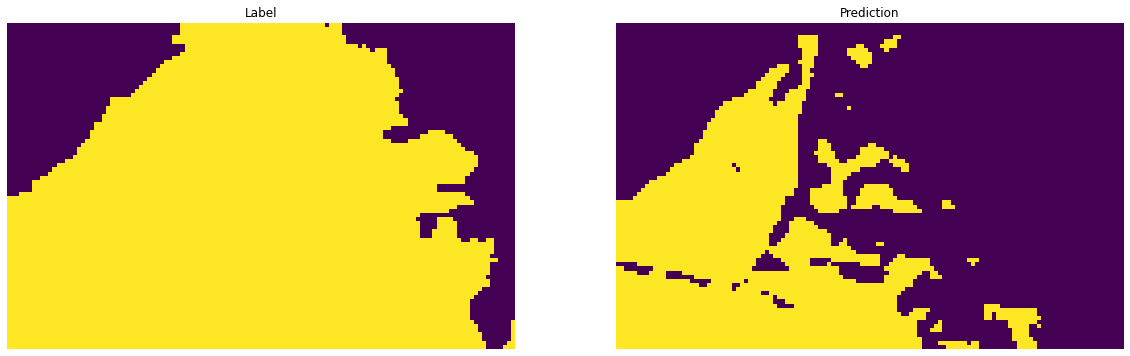

In [ ]:
# calculate the metrics
# Labels
df_label,df_pred,cm,f1,precision,recall,accuracy = validation.simple_burnt_validation(representation_diff,fire_shp,sampling = True)

## Calculating the PR-AUC

In [ ]:
cosine_dist = "/content/drive/My Drive/FireCLR-Wildfires-Demo/distance_maps/demo_cos_dist.tif"

In [ ]:
df_label,df_pred = validation.generate_val_PRAUC(cosine_dist,fire_shp)

In [ ]:
true_changes = df_label.label.values
pred_change_scores = df_pred.label.values

print("We loaded %d labels and %d predictions" %(true_changes.shape[0], pred_change_scores.shape[0]))

We loaded 9717 labels and 9717 predictions


In [ ]:
pred_change_scores[np.isnan(pred_change_scores)] = 0.0
precision, recall, thresholds = validation.precision_recall(true_changes, pred_change_scores, mask=False)
area_under_precision_curve = auc(recall, precision)
print("AUPRC = ", area_under_precision_curve)

AUPRC =  0.9620272735481722


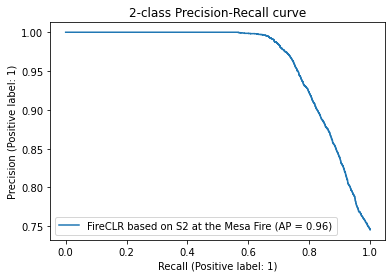

In [ ]:
display = PrecisionRecallDisplay.from_predictions(true_changes, pred_change_scores, name="FireCLR based on S2 at the Mesa Fire")
_ = display.ax_.set_title("2-class Precision-Recall curve")
plt.show()